# **02 · French Bakery: análisis exploratorio y preprocesamiento**

Este notebook analiza las ventas de una panadería francesa y las deja en el formato común que comparten los tres datasets del proyecto. A diferencia de ddop, los datos vienen como transacciones, así que primero hay que llevarlos a ventas diarias por producto.

## **0. Contexto y fuente**

- **Origen:** tickets de venta de una panadería artesanal en Francia, de enero de 2021 a septiembre de 2022.
- **Publicación:** dataset *French Bakery Daily Sales* en Kaggle (usuario matthieugimbert). La licencia indica "Data files © Original Authors", así que se usa con fines académicos citando la fuente, y se menciona como limitación.
- **Por qué se usa:** es un negocio pequeño de un solo local con muchos productos distintos (panes, bollería, repostería, bebidas y sándwiches), que es justo la variedad que le falta a ddop.
- **Papel en el proyecto:** entrenamiento del modelo global, junto con ddop.
- **Limitaciones conocidas:** es un solo local, en una zona turística, por lo que tiene un pico de ventas en verano que Sakura no comparte.

## **1. Descarga reproducible**

Kaggle pide iniciar sesión para descargar, así que los datos se obtienen de una copia pública en GitHub con las mismas 234,005 filas, fijando el commit para que siempre sean los mismos archivos. Se guardan en `data/raw/french_bakery/`, que también se versiona en el repositorio; si ya existen, no se vuelven a descargar.

In [1]:
from pathlib import Path

import pandas as pd
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "french_bakery"
RAW.mkdir(parents=True, exist_ok=True)

# Copia en GitHub del dataset de Kaggle (commit de marzo de 2026)
COMMIT = "4fd113c80f18b7bd95986ceed55cb80014fd0396"
URL = f"https://raw.githubusercontent.com/anaya33/transaction-pattern-analysis/{COMMIT}/Bakery%20sales.csv"

path = RAW / "bakery_sales.csv"
if not path.exists():
    response = requests.get(URL, timeout=120)
    response.raise_for_status()
    path.write_bytes(response.content)
print(f"{path.name}: {path.stat().st_size / 1024:,.0f} KB")

bakery_sales.csv: 14,332 KB


## **2. Composición**

Cada fila es **un producto dentro de un ticket**: si un cliente compra tres croissants y una baguette, su ticket ocupa dos filas.

- Columna sin nombre: índice de la fila, sin significado.
- `date`: el día de la venta.
- `time`: la hora de la venta.
- `ticket_number`: número del ticket, es decir, de la compra.
- `article`: nombre del producto.
- `Quantity`: unidades de ese producto en ese ticket. **Es la base de la variable que se quiere predecir.**
- `unit_price`: precio por unidad, en texto con coma decimal y símbolo de euro (por ejemplo `"1,20 €"`).

In [2]:
raw = pd.read_csv(path, index_col=0, parse_dates=["date"])
raw.head()

,date,time,ticket_number,article,Quantity,unit_price
0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,"0,90 €"
1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,"1,20 €"
4,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,"1,20 €"
5,2021-01-02,09:14,150041.0,PAIN,1.0,"1,15 €"
8,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,"1,20 €"


In [3]:
raw.dtypes

date             datetime64[us]
time                        str
ticket_number           float64
article                     str
Quantity                float64
unit_price                  str
dtype: object

In [4]:
n_days = raw["date"].nunique()
calendar_days = (raw["date"].max() - raw["date"].min()).days + 1

print(f"Filas: {len(raw):,}")
print(f"Tickets: {raw['ticket_number'].nunique():,} | Productos: {raw['article'].nunique()}")
print(f"Rango: {raw['date'].min().date()} a {raw['date'].max().date()} ({calendar_days} días de calendario, {n_days} con ventas)")

Filas: 234,005


Tickets: 136,451 | Productos: 149
Rango: 2021-01-02 a 2022-09-30 (637 días de calendario, 600 con ventas)


## **3. Calidad**

La celda siguiente revisa valores nulos, filas repetidas, cantidades con decimales y cantidades negativas.

In [5]:
checks = {
    "Valores nulos": int(raw.isna().sum().sum()),
    "Filas repetidas (todas las columnas)": int(raw.duplicated().sum()),
    "Cantidades con decimales": int((raw["Quantity"] % 1 != 0).sum()),
    "Cantidades negativas": int((raw["Quantity"] < 0).sum()),
    "Cantidades en cero": int((raw["Quantity"] == 0).sum()),
}
pd.Series(checks, name="Cantidad").to_frame()

,Cantidad
Valores nulos,0
Filas repetidas (todas las columnas),1210
Cantidades con decimales,0
Cantidades negativas,1295
Cantidades en cero,0


El precio viene como texto, así que se convierte a número para poder analizarlo.

In [6]:
raw["price"] = (
    raw["unit_price"].str.replace("€", "", regex=False).str.replace(",", ".", regex=False).str.strip().astype(float)
)
raw[["unit_price", "price"]].drop_duplicates().head()

,unit_price,price
0,"0,90 €",0.90
1,"1,20 €",1.20
5,"1,15 €",1.15
12,"1,10 €",1.10
15,"1,05 €",1.05


Las cantidades negativas requieren una decisión, así que primero se revisa cómo se ven: en qué productos aparecen, de qué tamaño son y si tienen una venta positiva del mismo producto en el mismo ticket, lo que indicaría una corrección de caja.

In [7]:
negatives = raw[raw["Quantity"] < 0]
positives = raw[raw["Quantity"] > 0]

same_ticket = negatives.merge(positives[["ticket_number", "article"]].drop_duplicates(), on=["ticket_number", "article"], how="left", indicator=True)
print(f"Filas negativas: {len(negatives):,} ({len(negatives) / len(raw):.2%} de las filas)")
print(f"Con una venta positiva del mismo producto en el mismo ticket: {(same_ticket['_merge'] == 'both').mean():.0%}")
print(f"Unidades negativas: {int(-negatives['Quantity'].sum()):,} de {int(positives['Quantity'].sum()):,} vendidas ({-negatives['Quantity'].sum() / positives['Quantity'].sum():.2%})")

negatives["article"].value_counts().head(8).rename("Filas negativas").to_frame()

Filas negativas: 1,295 (0.55% de las filas)
Con una venta positiva del mismo producto en el mismo ticket: 1%
Unidades negativas: 2,201 de 362,189 vendidas (0.61%)


,Filas negativas
article,
TRADITIONAL BAGUETTE,340
BANETTE,110
COUPE,84
FORMULE SANDWICH,81
BAGUETTE,67
CROISSANT,60
PAIN AU CHOCOLAT,52
SPECIAL BREAD,31


In [8]:
negatives["Quantity"].describe()[["min", "25%", "50%", "75%", "max"]].rename("Cantidad negativa").to_frame()

,Cantidad negativa
min,-200.0
25%,-2.0
50%,-1.0
75%,-1.0
max,-1.0


In [9]:
negatives.sort_values("Quantity").head(8)[["date", "time", "ticket_number", "article", "Quantity", "unit_price"]]

,date,time,ticket_number,article,Quantity,unit_price
110378,2021-06-12,09:58,179932.0,CAFE OU EAU,-200.0,"1,00 €"
238857,2021-10-15,10:24,214565.0,PAIN AU CHOCOLAT,-18.0,"1,20 €"
238856,2021-10-15,10:24,214565.0,CROISSANT,-17.0,"1,10 €"
93984,2021-05-23,08:50,175484.0,TRADITIONAL BAGUETTE,-13.0,"1,20 €"
93985,2021-05-23,08:50,175484.0,CROISSANT,-12.0,"1,10 €"
427545,2022-07-17,11:12,266157.0,CROISSANT,-10.0,"1,20 €"
104287,2021-06-04,12:07,178280.0,TRADITIONAL BAGUETTE,-10.0,"1,20 €"
379515,2022-05-28,10:40,253014.0,TRADITIONAL BAGUETTE,-10.0,"1,25 €"


**Conclusiones de la sección:**

- **Filas repetidas:** se conservan. Son el mismo producto marcado dos veces en un mismo ticket (por ejemplo, dos `COUPE`, el servicio de cortar el pan), es decir, ventas reales registradas por separado. Al sumar por día se obtiene la cantidad correcta.
- **Cantidades negativas:** se restan de las ventas del día. Son pequeñas (mediana de −1), casi nunca tienen una venta del mismo producto en el mismo ticket y ocurren durante todo el horario de atención, por lo que se interpretan como devoluciones o anulaciones registradas en caja. Representan el 0.61 % de las unidades y, al restarlas, ningún día queda con ventas negativas.

## **4. Agregación a ventas diarias**

El modelo trabaja con una fila por producto y día, así que las transacciones se suman por día, incluidas las cantidades negativas. Después se reconstruye el calendario completo, porque los días sin ventas no aparecen en los datos:

- Si en un día **no hay ningún ticket**, el local estaba cerrado (`is_open = False`). Es la misma regla que en ddop: ningún producto vendió.
- Si el local abrió pero un producto no aparece en ningún ticket, ese producto vendió 0.

In [10]:
daily_sales = raw.groupby(["article", "date"])["Quantity"].sum().rename("sales").reset_index()

calendar = pd.date_range(raw["date"].min(), raw["date"].max(), freq="D")
open_dates = set(raw["date"].unique())
grid = pd.MultiIndex.from_product([sorted(raw["article"].unique()), calendar], names=["article", "date"]).to_frame(index=False)

df = grid.merge(daily_sales, on=["article", "date"], how="left")
df["sales"] = df["sales"].fillna(0).astype(int)
df["is_open"] = df["date"].isin(open_dates)
df["day_of_week"] = df["date"].dt.day_of_week

print(f"Filas: {len(df):,} ({df['article'].nunique()} productos × {len(calendar)} días)")
print(f"Días cerrados: {len(calendar) - len(open_dates)} de {len(calendar)}")
df.head()

Filas: 94,913 (149 productos × 637 días)
Días cerrados: 37 de 637


,article,date,sales,is_open,day_of_week
0,.,2021-01-02,0,True,5
1,.,2021-01-03,0,True,6
2,.,2021-01-04,0,True,0
3,.,2021-01-05,0,True,1
4,.,2021-01-06,0,False,2


Los días cerrados se concentran en los miércoles. La tabla siguiente muestra cuántos miércoles abrió el local cada mes.

In [11]:
closed_days = pd.Series(calendar[~calendar.isin(open_dates)])
print("Días cerrados por día de la semana:", closed_days.dt.day_name().value_counts().to_dict())

wednesdays = pd.Series(calendar[calendar.day_of_week == 2])
pd.DataFrame({
    "Miércoles": wednesdays.groupby(wednesdays.dt.to_period("M")).size(),
    "Abiertos": wednesdays[wednesdays.isin(open_dates)].groupby(wednesdays.dt.to_period("M")).size(),
}).fillna(0).astype(int).T

Días cerrados por día de la semana: {'Wednesday': 29, 'Monday': 3, 'Tuesday': 2, 'Thursday': 2, 'Saturday': 1}


,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,...,2021-12,2022-01,2022-02,2022-03,2022-04,2022-05,2022-06,2022-07,2022-08,2022-09
Miércoles,4,4,5,4,4,5,4,4,5,4,...,5,4,4,5,4,4,5,4,5,4
Abiertos,0,0,0,3,3,5,4,4,5,4,...,2,0,0,5,4,3,5,4,5,4


## **5. Selección de productos**

No todos los artículos de la caja sirven como serie. Se aplican tres reglas:

1. **Excluir lo que no es un producto que se produce:** `.` (un error de registro), `COUPE` (el servicio de cortar el pan), los `DIVERS …` y `CAFE OU EAU` (teclas de caja que mezclan productos distintos; la segunda cobra igual un café preparado que un agua embotellada), y `BOISSON 33CL` y `SUCETTE` (una bebida embotellada y una paleta que se compran y se revenden; no se echan a perder, así que el problema *newsvendor* no les aplica).
2. **Recortar cada serie a su vida activa**, desde su primera hasta su última venta. Antes de aparecer o después de dejar de venderse, el producto no existía, así que esos ceros no son demanda.
3. **Conservar los productos que se venden en al menos el 50 % de los días abiertos de su vida activa**, con un mínimo de 90 días abiertos, para que alcancen para varias ventanas de entrenamiento.

In [12]:
not_products = [".", "COUPE", "CAFE OU EAU", "BOISSON 33CL", "SUCETTE"]
excluded = sorted(a for a in df["article"].unique() if a in not_products or a.startswith("DIVERS"))
print("Excluidos por no ser productos:", excluded)
df = df[~df["article"].isin(excluded)]

Excluidos por no ser productos: ['.', 'BOISSON 33CL', 'CAFE OU EAU', 'COUPE', 'DIVERS BOISSONS', 'DIVERS BOULANGERIE', 'DIVERS CONFISERIE', 'DIVERS PATISSERIE', 'DIVERS SANDWICHS', 'DIVERS VIENNOISERIE', 'SUCETTE']


In [13]:
sold = df[df["sales"] != 0]
life = sold.groupby("article")["date"].agg(first_sale="min", last_sale="max")
df = df.merge(life, on="article")
df = df[(df["date"] >= df["first_sale"]) & (df["date"] <= df["last_sale"])].drop(columns=["first_sale", "last_sale"])

open_in_life = df[df["is_open"]]
coverage = pd.DataFrame({
    "dias_abiertos": open_in_life.groupby("article").size(),
    "dias_con_venta": open_in_life[open_in_life["sales"] != 0].groupby("article").size(),
}).fillna(0)
coverage["cobertura"] = coverage["dias_con_venta"] / coverage["dias_abiertos"]

keep = coverage[(coverage["cobertura"] >= 0.5) & (coverage["dias_abiertos"] >= 90)].index
print(f"Productos después de excluir: {len(coverage)} | Conservados: {len(keep)}")

Productos después de excluir: 137 | Conservados: 47


Para dejar visible el efecto del umbral, la tabla siguiente muestra cuántos productos quedarían con distintos valores. Entre 50 % y 75 % se pierden sobre todo postres (Paris-Brest, Flan, Mille-feuilles), que se venden de forma más irregular que los panes y son justo el tipo de producto que interesa a Restocker.

In [14]:
eligible = coverage[coverage["dias_abiertos"] >= 90]
pd.Series({f"{t:.0%}": int((eligible["cobertura"] >= t).sum()) for t in [0.3, 0.5, 0.6, 0.7, 0.75, 0.9]}, name="Productos").to_frame().T

,30%,50%,60%,70%,75%,90%
Productos,58,47,41,34,32,22


In [15]:
df = df[df["article"].isin(keep)]
coverage.loc[keep].sort_values("cobertura", ascending=False).round(2)

,dias_abiertos,dias_con_venta,cobertura
article,,,
BAGUETTE,600,600,1.00
BANETTE,600,600,1.00
TRADITIONAL BAGUETTE,600,600,1.00
CROISSANT,600,599,1.00
SPECIAL BREAD,600,598,1.00
PAIN AU CHOCOLAT,600,598,1.00
BOULE 400G,600,597,1.00
BANETTINE,600,595,0.99
CAMPAGNE,600,595,0.99


In [16]:
print(f"Filas: {len(df):,} | Productos: {df['article'].nunique()} | Ceros con el local abierto: {int(((df['sales'] == 0) & df['is_open']).sum()):,}")

Filas: 27,953 | Productos: 47 | Ceros con el local abierto: 4,093


## **6. Distribuciones y escala**

Como en ddop, esta sección usa solo los días con el local abierto. Con 47 productos, en lugar de un histograma por producto se resume cada serie con su venta promedio y su proporción de días en cero.

In [17]:
import matplotlib.pyplot as plt

open_days = df[df["is_open"]]
series = open_days.groupby("article")["sales"].agg(promedio="mean", mediana="median", maximo="max")
series["dias_en_cero"] = open_days.groupby("article")["sales"].apply(lambda s: (s == 0).mean())
series.describe().loc[["min", "25%", "50%", "75%", "max"]].round(2)

,promedio,mediana,maximo,dias_en_cero
min,0.76,1.0,4.0,0.00
25%,2.02,1.5,13.0,0.02
50%,3.97,4.0,18.0,0.12
75%,6.29,6.0,29.5,0.32
max,195.77,154.0,707.0,0.50


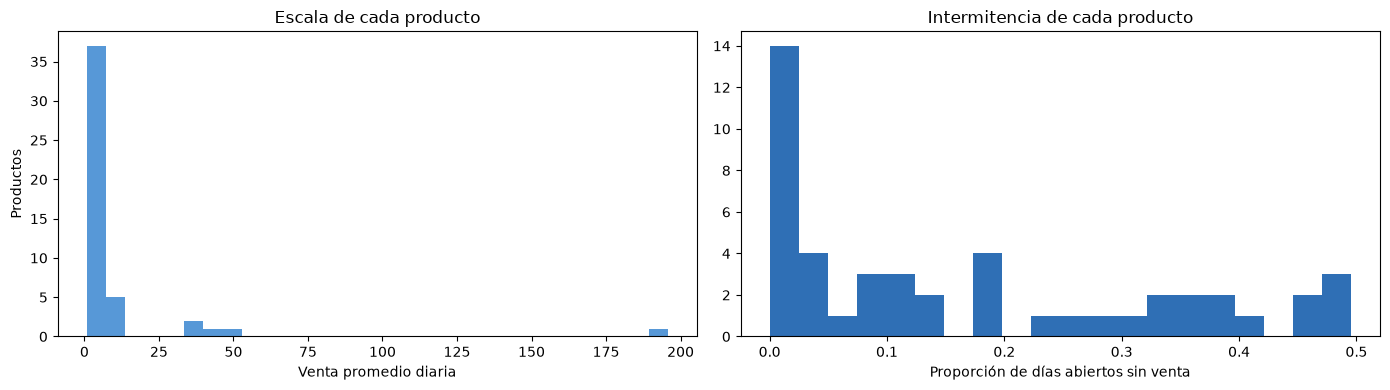

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(series["promedio"], bins=30, color="#5798d7")
axes[0].set_xlabel("Venta promedio diaria")
axes[0].set_ylabel("Productos")
axes[0].set_title("Escala de cada producto")
axes[1].hist(series["dias_en_cero"], bins=20, color="#2f6fb5")
axes[1].set_xlabel("Proporción de días abiertos sin venta")
axes[1].set_title("Intermitencia de cada producto")
plt.tight_layout()
plt.show()

Para detectar valores atípicos, cada venta se compara contra la mediana de su propia serie, igual que en ddop.

In [19]:
median = open_days.groupby("article")["sales"].transform("median")
ratio = open_days["sales"] / median.where(median > 0)
for k in [3, 5, 10]:
    print(f"Días con venta mayor a {k} veces la mediana de su serie: {int((ratio > k).sum()):,} ({(ratio > k).mean():.2%})")

open_days.assign(veces_mediana=ratio.round(1)).nlargest(8, "veces_mediana")[["date", "article", "sales", "veces_mediana"]]

Días con venta mayor a 3 veces la mediana de su serie: 1,306 (4.95%)
Días con venta mayor a 5 veces la mediana de su serie: 399 (1.51%)
Días con venta mayor a 10 veces la mediana de su serie: 38 (0.14%)


,date,article,sales,veces_mediana
39715,2021-08-11,GRAND FAR BRETON,18,18.0
38172,2022-08-14,GD KOUIGN AMANN,17,17.0
40062,2022-07-24,GRAND FAR BRETON,17,17.0
62384,2022-08-20,PT NANTAIS,17,17.0
39719,2021-08-15,GRAND FAR BRETON,16,16.0
39712,2021-08-08,GRAND FAR BRETON,15,15.0
62014,2021-08-15,PT NANTAIS,15,15.0
37716,2021-05-15,GD KOUIGN AMANN,14,14.0


**Conclusiones de la sección:**

- **Escala:** la mitad de los productos vende menos de 4 unidades al día, una escala de negocio pequeño. La baguette tradicional, con 196 al día, muestra que también aquí cada serie debe normalizarse por su propia escala.
- **Valores atípicos:** no se eliminan. Los más extremos son ventas de julio y agosto (temporada turística); son ventas reales, y quitarlos por verse raros no sería una regla consistente con la de ddop.

## **7. Patrones temporales**

Cada venta se divide entre el promedio de su serie en días abiertos, para comparar productos de escalas distintas. Un valor de 1.3 significa "30 % más de lo normal para ese producto".

In [20]:
open_days = open_days.assign(relative=open_days["sales"] / open_days.groupby("article")["sales"].transform("mean"))
day_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

weekly = open_days.groupby(["day_of_week", "article"])["relative"].mean().unstack()
summary = pd.DataFrame({"promedio": weekly.mean(axis=1), "p25": weekly.quantile(0.25, axis=1), "p75": weekly.quantile(0.75, axis=1)})
summary.index = day_names
summary.round(2)

,promedio,p25,p75
Lun,0.88,0.81,0.97
Mar,0.85,0.70,0.95
Mié,0.90,0.78,0.95
Jue,0.89,0.82,0.97
Vie,0.96,0.86,1.02
Sáb,1.10,1.02,1.19
Dom,1.37,1.17,1.59


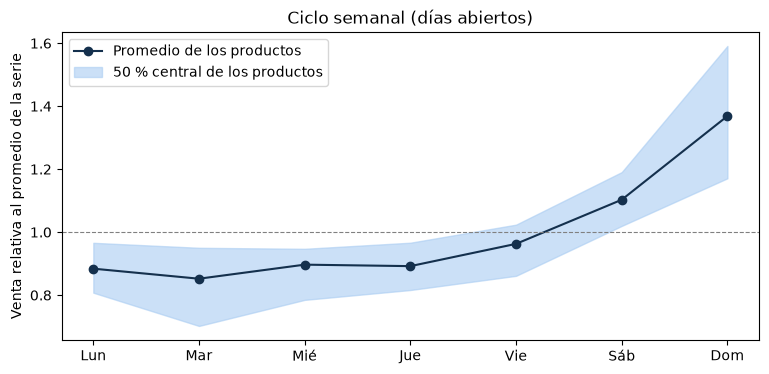

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(day_names, summary["promedio"], marker="o", color="#14304d", label="Promedio de los productos")
ax.fill_between(day_names, summary["p25"], summary["p75"], color="#a9ccf2", alpha=0.6, label="50 % central de los productos")
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Ciclo semanal (días abiertos)")
ax.legend()
plt.show()

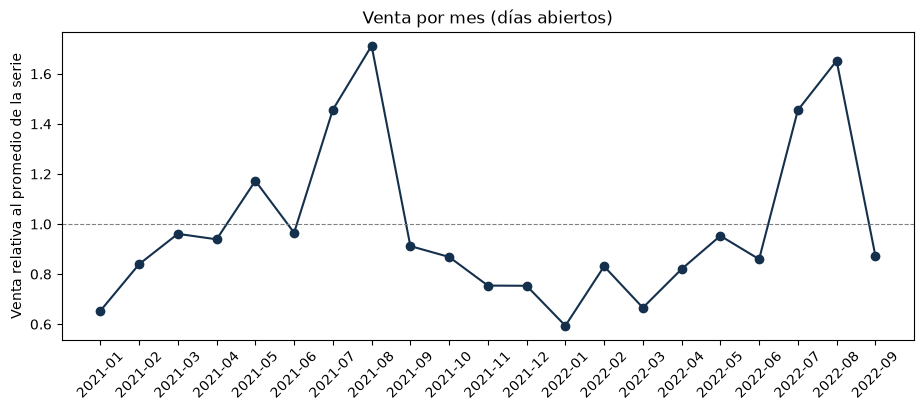

In [22]:
monthly = open_days.groupby(open_days["date"].dt.to_period("M"))["relative"].mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", color="#14304d")
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Venta por mes (días abiertos)")
ax.tick_params(axis="x", rotation=45)
plt.show()

La autocorrelación se calcula igual que en ddop: por serie, con los cierres y los días fuera de la vida del producto como faltantes, y se promedia.

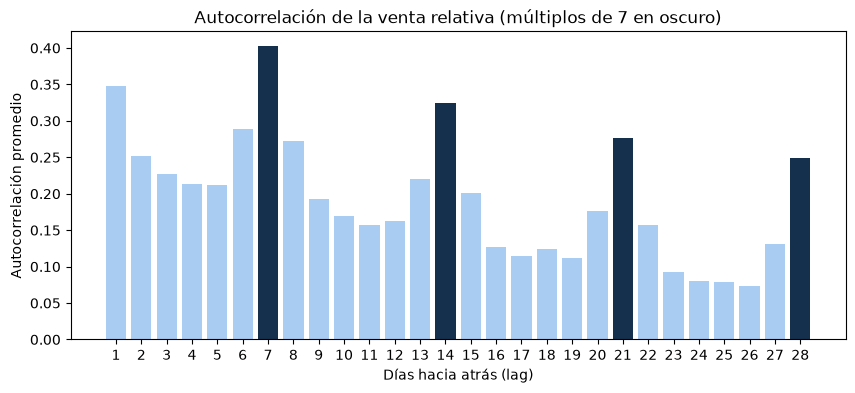

In [23]:
def series_autocorr(group, lags):
    s = group.set_index("date")["relative"].reindex(pd.date_range(group["date"].min(), group["date"].max()))
    return pd.Series({lag: s.autocorr(lag) for lag in lags})

lags = range(1, 29)
acf = open_days.groupby("article")[["date", "relative"]].apply(series_autocorr, lags=lags).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(acf.index, acf.values, color=["#14304d" if lag % 7 == 0 else "#a9ccf2" for lag in acf.index])
ax.set_xticks(list(lags))
ax.set_xlabel("Días hacia atrás (lag)")
ax.set_ylabel("Autocorrelación promedio")
ax.set_title("Autocorrelación de la venta relativa (múltiplos de 7 en oscuro)")
plt.show()

**Conclusiones de la sección:**

- **Ciclo semanal:** el fin de semana vende más y el domingo es el día más alto (1.37), casi la misma forma que en ddop. Que dos panaderías de países distintos compartan el ciclo semanal respalda entrenar un solo modelo con ambos datasets.
- **Ciclo anual:** en julio y agosto se vende entre 1.5 y 1.7 veces lo normal por el turismo. No se modela, igual que en ddop: la normalización con los días de cada ventana ajusta el nivel a la temporada en que se está prediciendo. La limitación son los cambios bruscos de nivel, como el inicio de julio o de septiembre, donde la ventana todavía refleja la temporada anterior.
- **Autocorrelación:** el pico sigue en 7 días, pero el día anterior también pesa (0.35) y la relación baja despacio, es decir, el nivel reciente importa más que en ddop. Por eso el tamaño de la ventana (14 o 28 días) se probará como una iteración del entrenamiento.

## **8. Decisiones de preprocesamiento**

| # | Decisión | Justificación | Sección |
| :- | :- | :- | :- |
| 1 | Las filas repetidas se conservan. | Son el mismo producto marcado dos veces en un ticket, es decir, ventas reales. | 3 |
| 2 | Las cantidades negativas se restan de las ventas del día. | Se interpretan como devoluciones o anulaciones (mediana de −1, durante todo el horario). Son el 0.61 % de las unidades y ningún día queda negativo. | 3 |
| 3 | Las transacciones se suman por producto y día, y se reconstruye el calendario completo. | El modelo trabaja con una fila por producto y día, y los días sin ventas no aparecen en los datos. | 4 |
| 4 | Un día sin ningún ticket es un cierre (`is_open = False`). | Es la misma regla que en ddop. Los cierres son sobre todo miércoles de invierno. | 4 |
| 5 | Si el local abrió y un producto no aparece, ese producto vendió 0. | Es un cero real: el local abrió y el producto no se vendió. | 4 |
| 6 | Se excluyen `.`, `COUPE`, los `DIVERS …`, `CAFE OU EAU`, `BOISSON 33CL` y `SUCETTE`. | No son productos que se produzcan: un error de registro, un servicio, teclas de caja que mezclan productos, y una bebida y un dulce que se revenden y no se echan a perder. | 5 |
| 7 | Cada producto se recorta a su vida activa, de la primera a la última venta. | Antes de aparecer o después de desaparecer el producto no existía, así que esos ceros no son demanda. | 5 |
| 8 | Se conservan los productos vendidos en al menos el 50 % de los días abiertos de su vida, con un mínimo de 90 días abiertos. | Las series casi vacías confunden al modelo; un umbral más alto (75 %) eliminaría casi todos los postres. | 5 |
| 9 | No se eliminan valores atípicos. | Corresponden a la temporada de verano o a pedidos reales. | 6 |
| 10 | No se modela el ciclo anual; cada ventana se normaliza con sus propios días de entrada. | El pico de verano es turístico y propio de este local; la normalización ajusta el nivel a la temporada. | 7 |
| 11 | El tamaño de la ventana (14 o 28 días) se decide con una iteración del entrenamiento. | El nivel reciente pesa más que en ddop. | 7 |
| 12 | Los feriados de Francia se agregan en el notebook de unificación. | Se construyen con la misma lógica para los tres datasets. | — |

## **9. Exportar al formato común**

Se guarda con la misma estructura que ddop: `dataset`, `store_id`, `product_id`, `date`, `sales` e `is_open`. Como es un solo local, todas las filas tienen el mismo `store_id`.

In [24]:
processed = pd.DataFrame({
    "dataset": "french_bakery",
    "store_id": "french_bakery_1",
    "product_id": "french_bakery_" + df["article"].str.lower().str.replace(" ", "_", regex=False),
    "date": df["date"],
    "sales": df["sales"],
    "is_open": df["is_open"],
}).sort_values(["product_id", "date"]).reset_index(drop=True)

OUT = ROOT / "data" / "processed" / "french_bakery.parquet"
processed.to_parquet(OUT, index=False)

print(f"Guardado en {OUT.relative_to(ROOT)} ({OUT.stat().st_size / 1024:,.0f} KB)")
print(f"Filas: {len(processed):,} | Series: {processed['product_id'].nunique()} | Días cerrados: {int((~processed['is_open']).sum()):,} filas")
processed.head()

Guardado en data/processed/french_bakery.parquet (47 KB)
Filas: 27,953 | Series: 47 | Días cerrados: 1,593 filas


,dataset,store_id,product_id,date,sales,is_open
0,french_bakery,french_bakery_1,french_bakery_baguette,2021-01-02,46,True
1,french_bakery,french_bakery_1,french_bakery_baguette,2021-01-03,35,True
2,french_bakery,french_bakery_1,french_bakery_baguette,2021-01-04,30,True
3,french_bakery,french_bakery_1,french_bakery_baguette,2021-01-05,29,True
4,french_bakery,french_bakery_1,french_bakery_baguette,2021-01-06,0,False
